### Exploratory Data Analysis

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 42
np.set_printoptions(precision=2, suppress=True)

In [8]:
filename = 'data/student_dropout.csv'
df = pd.read_csv(filename)

In [9]:
df.head()

,student_id,age_at_enrollment,gender,international,first_generation,scholarship,program,high_school_gpa,admission_score,attendance_pct,...,ai_tool_hours_week,stress_index,commute_km,financial_aid_usd_k,tuition_debt,sem1_gpa,sem1_credits_passed_pct,sem2_gpa,final_gpa,dropout
0,S00001,18,Male,0,0,1,Law,1.84,60,75.9,...,3.0,6.1,8.8,5.0,0,1.41,68.8,1.19,1.32,1
1,S00002,18,Male,1,0,0,Natural Sciences,4.00,89,90.2,...,0.5,5.0,12.7,3.6,0,3.49,87.3,3.35,3.59,0
2,S00003,18,Male,0,0,0,Computer Science,3.21,65,81.9,...,1.0,6.8,10.5,5.3,0,2.67,73.3,2.48,2.84,0
3,S00004,18,Female,0,1,0,Engineering,2.10,57,83.6,...,2.7,5.2,31.7,0.0,0,3.02,84.0,3.31,3.15,0
4,S00005,19,Female,0,0,0,Natural Sciences,3.31,55,83.4,...,1.0,6.7,6.1,2.2,0,2.01,73.2,1.96,2.28,0


In [10]:
df.shape

(12000, 23)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               12000 non-null  str    
 1   age_at_enrollment        12000 non-null  int64  
 2   gender                   12000 non-null  str    
 3   international            12000 non-null  int64  
 4   first_generation         12000 non-null  int64  
 5   scholarship              12000 non-null  int64  
 6   program                  12000 non-null  str    
 7   high_school_gpa          12000 non-null  float64
 8   admission_score          12000 non-null  int64  
 9   attendance_pct           12000 non-null  float64
 10  study_hours_week         12000 non-null  float64
 11  part_time_job_hours      12000 non-null  int64  
 12  lms_logins_week          12000 non-null  float64
 13  ai_tool_hours_week       12000 non-null  float64
 14  stress_index             12000 no

In [12]:
target = "dropout"


#### Feature groups
The dataset has 12,000 students and 23 columns:
- `student_id`: an identifier with no predictive value, so we drop it.
- **Categorical (nominal)**: `gender`, `program`. These need encoding (e.g. one-hot) before scikit-learn's Random Forest / Bagging.
- **Binary flags (0/1)**: `international`, `first_generation`, `scholarship`, `tuition_debt`.
- **Numerical**: demographics, academic background, engagement, lifestyle and semester performance.
- **Target**: `dropout` (1 = dropped out).

In [13]:
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

id_col = "student_id"
categorical_cols = ["gender", "program"]
binary_cols = ["international", "first_generation", "scholarship", "tuition_debt"]
numerical_cols = [c for c in df.columns if c not in categorical_cols + binary_cols + [id_col, target]]

print(f"Categorical ({len(categorical_cols)}): {categorical_cols}")
print(f"Binary      ({len(binary_cols)}): {binary_cols}")
print(f"Numerical   ({len(numerical_cols)}): {numerical_cols}")

Categorical (2): ['gender', 'program']
Binary      (4): ['international', 'first_generation', 'scholarship', 'tuition_debt']
Numerical   (15): ['age_at_enrollment', 'high_school_gpa', 'admission_score', 'attendance_pct', 'study_hours_week', 'part_time_job_hours', 'lms_logins_week', 'ai_tool_hours_week', 'stress_index', 'commute_km', 'financial_aid_usd_k', 'sem1_gpa', 'sem1_credits_passed_pct', 'sem2_gpa', 'final_gpa']


#### Data quality: missing values, duplicates, IDs

In [14]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "  none")
print(f"\nDuplicated rows: {df.duplicated().sum()}")
print(f"Duplicated rows ignoring student_id: {df.drop(columns=id_col).duplicated().sum()}")
print(f"Unique student_id: {df[id_col].nunique()} / {len(df)}")

Missing values per column:
  none

Duplicated rows: 0
Duplicated rows ignoring student_id: 0
Unique student_id: 12000 / 12000


In [15]:
df = df.drop(columns=id_col)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age_at_enrollment,12000.00,20.13,2.22,18.00,19.00,19.00,21.00,38.00
international,12000.00,0.12,0.33,0.00,0.00,0.00,0.00,1.00
first_generation,12000.00,0.30,0.46,0.00,0.00,0.00,1.00,1.00
scholarship,12000.00,0.25,0.43,0.00,0.00,0.00,1.00,1.00
high_school_gpa,12000.00,3.00,0.49,1.50,2.67,3.00,3.34,4.00
admission_score,12000.00,70.08,11.62,30.00,62.00,70.00,78.00,100.00
attendance_pct,12000.00,80.26,9.15,45.50,74.00,80.30,86.50,100.00
study_hours_week,12000.00,10.82,5.35,1.00,7.00,10.70,14.50,31.70
part_time_job_hours,12000.00,8.93,8.65,0.00,3.00,6.00,12.00,40.00
lms_logins_week,12000.00,5.38,3.50,0.50,3.00,4.50,6.80,40.00


In [16]:
for col in categorical_cols:
    print(df[col].value_counts(), "\n")

gender
Female        6235
Male          5507
Non-binary     258
Name: count, dtype: int64 

program
Computer Science     2172
Business             2079
Health Sciences      1738
Engineering          1658
Arts & Humanities    1434
Natural Sciences     1240
Education            1063
Law                   616
Name: count, dtype: int64 



#### Target distribution
Check class balance. If the classes are imbalanced, we should use a **stratified** train/test split and consider `class_weight="balanced"` (or `"balanced_subsample"` for Random Forest). We should also judge models on recall, F1 and ROC-AUC rather than accuracy alone.

,count,proportion
dropout,,
0,9360,0.78
1,2640,0.22


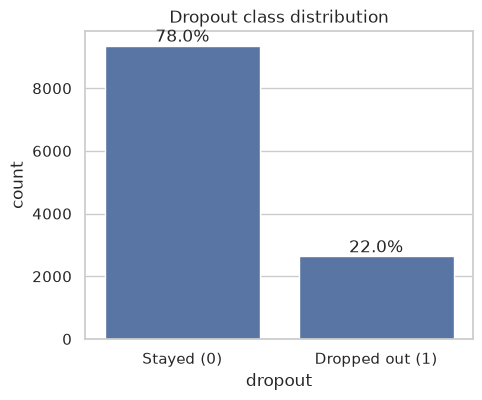

In [17]:
counts = df[target].value_counts().sort_index()
props = df[target].value_counts(normalize=True).sort_index()
display(pd.DataFrame({"count": counts, "proportion": props}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x=target, ax=ax)
for p, pct in zip(ax.patches, props):
    ax.annotate(f"{pct:.1%}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Dropout class distribution")
ax.set_xticks([0, 1], ["Stayed (0)", "Dropped out (1)"])
plt.show()

#### Numerical features: distributions by target

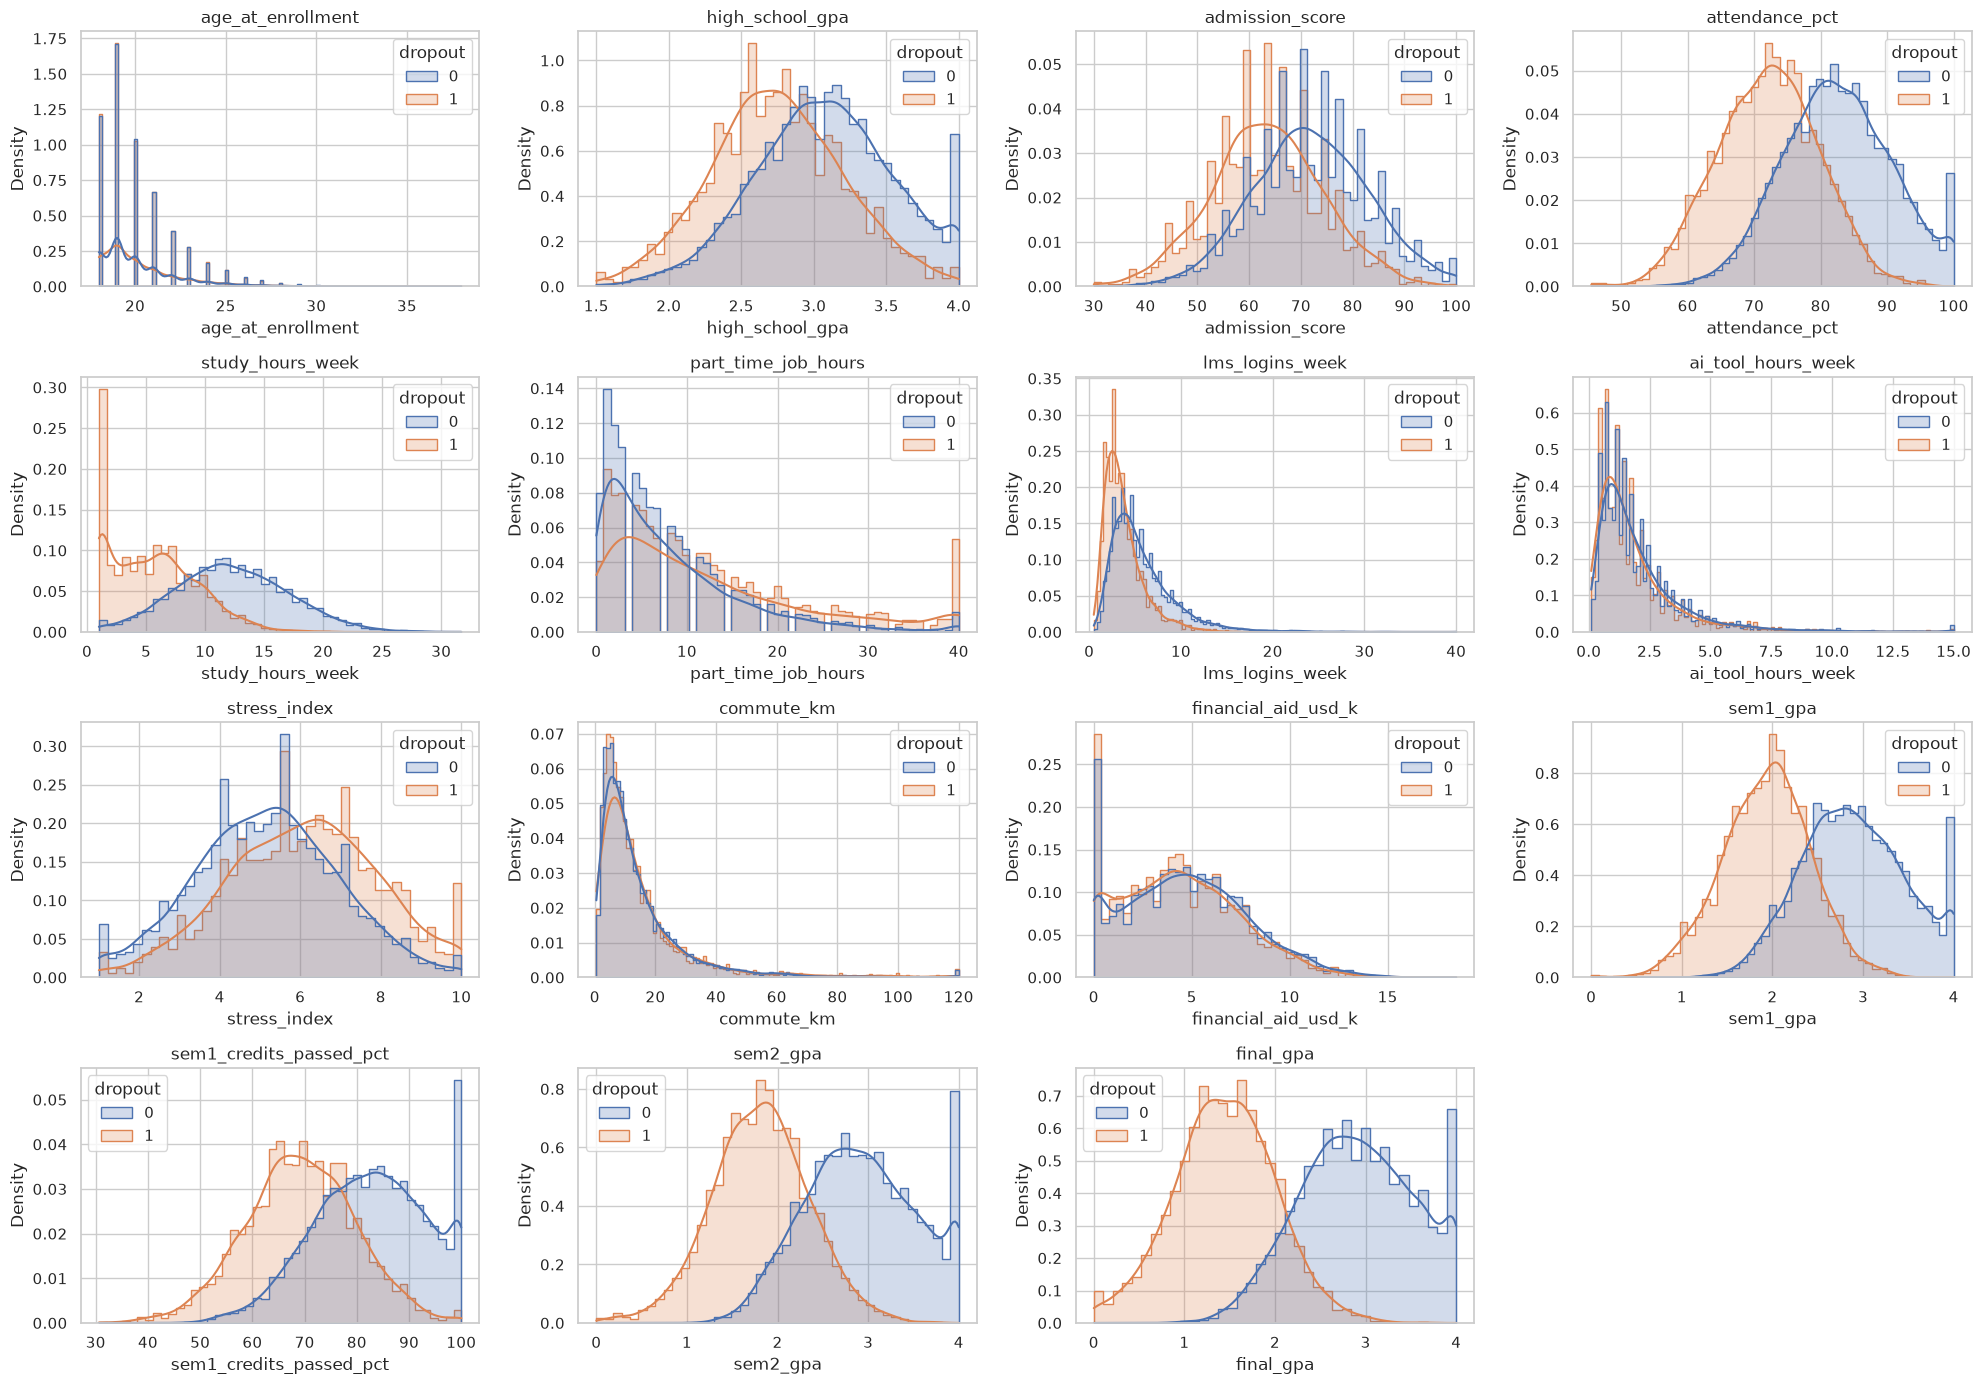

In [18]:
n_cols = 4
n_rows = int(np.ceil(len(numerical_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
for ax, col in zip(axes.flat, numerical_cols):
    sns.histplot(data=df, x=col, hue=target, kde=True, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(numerical_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

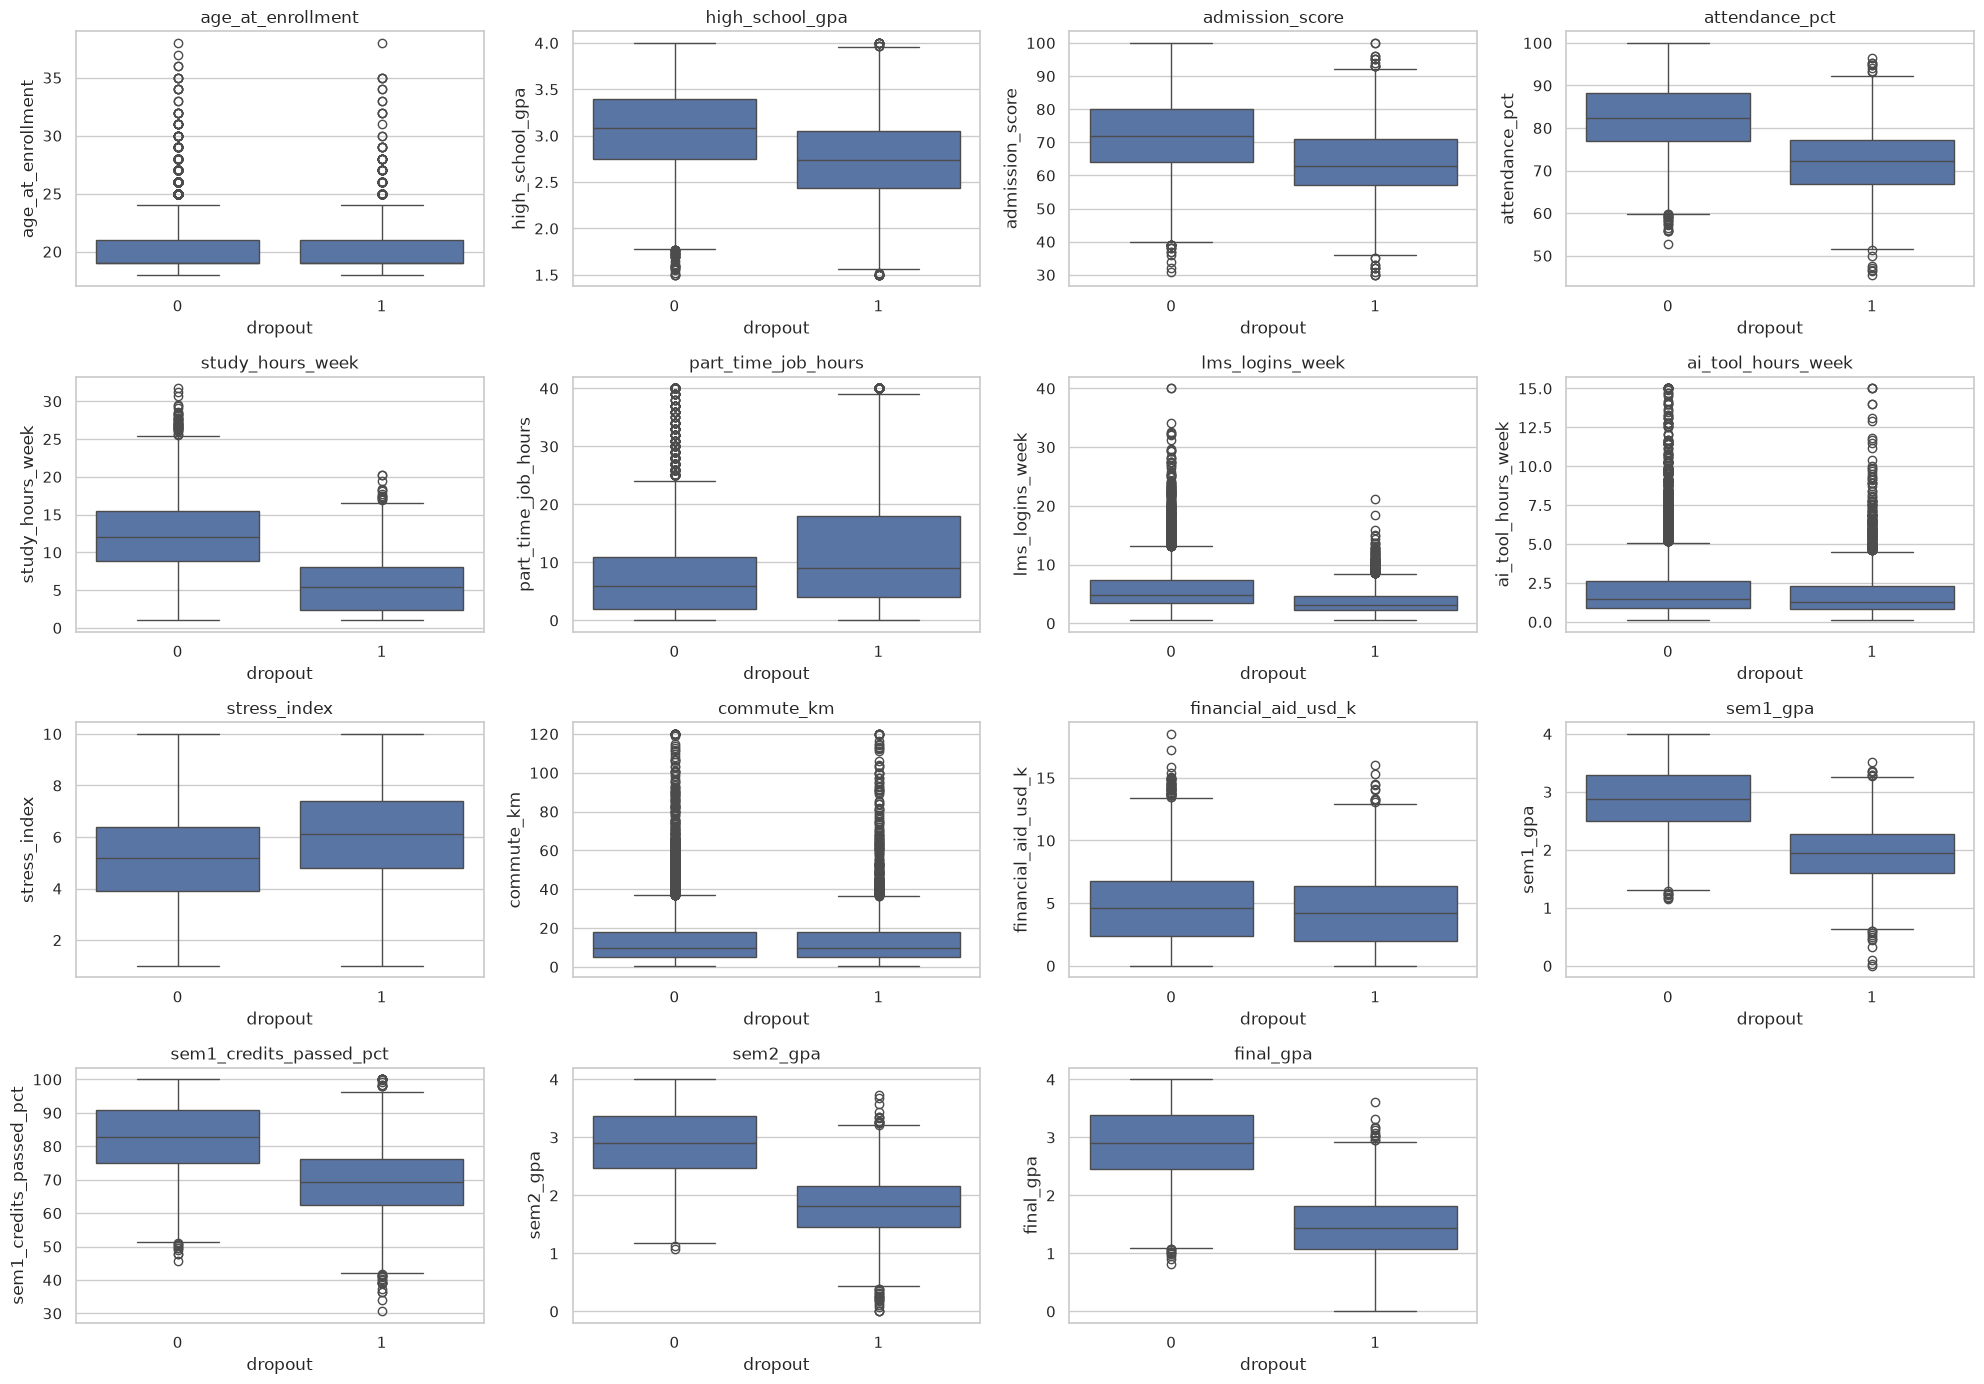

In [19]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
for ax, col in zip(axes.flat, numerical_cols):
    sns.boxplot(data=df, x=target, y=col, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(numerical_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [20]:
# Mean of each numerical feature per class, sorted by standardised mean difference
grouped = df.groupby(target)[numerical_cols].mean().T
grouped.columns = ["mean_stayed", "mean_dropout"]
grouped["std_mean_diff"] = (grouped["mean_dropout"] - grouped["mean_stayed"]) / df[numerical_cols].std()
grouped.sort_values("std_mean_diff", key=abs, ascending=False)

,mean_stayed,mean_dropout,std_mean_diff
final_gpa,2.91,1.44,-1.70
sem2_gpa,2.92,1.81,-1.47
sem1_gpa,2.89,1.93,-1.41
study_hours_week,12.29,5.63,-1.24
attendance_pct,82.57,72.08,-1.15
sem1_credits_passed_pct,82.53,69.20,-1.11
admission_score,71.93,63.51,-0.72
high_school_gpa,3.07,2.75,-0.66
lms_logins_week,5.83,3.76,-0.59
part_time_job_hours,7.98,12.29,0.50


#### Skewness and outliers
Tree-based models (Random Forest, Bagging of decision trees) do not need feature scaling and are robust to outliers and skewed distributions. We still check them here to make sure there are no data-entry errors.

In [21]:
q1, q3 = df[numerical_cols].quantile(0.25), df[numerical_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[numerical_cols] < q1 - 1.5 * iqr) | (df[numerical_cols] > q3 + 1.5 * iqr)).sum()
pd.DataFrame({
    "skew": df[numerical_cols].skew(),
    "n_outliers_iqr": outliers,
    "pct_outliers": outliers / len(df) * 100,
    "min": df[numerical_cols].min(),
    "max": df[numerical_cols].max(),
}).sort_values("skew", key=abs, ascending=False)

,skew,n_outliers_iqr,pct_outliers,min,max
commute_km,2.98,842,7.02,0.50,120.00
ai_tool_hours_week,2.74,804,6.70,0.10,15.00
lms_logins_week,2.19,495,4.12,0.50,40.00
age_at_enrollment,1.96,611,5.09,18.00,38.00
part_time_job_hours,1.58,735,6.12,0.00,40.00
final_gpa,-0.41,38,0.32,0.00,4.00
financial_aid_usd_k,0.41,54,0.45,0.00,18.50
sem1_credits_passed_pct,-0.26,36,0.30,30.60,100.00
sem2_gpa,-0.20,33,0.27,0.00,4.00
study_hours_week,0.19,38,0.32,1.00,31.70


#### Categorical and binary features: dropout rate per category

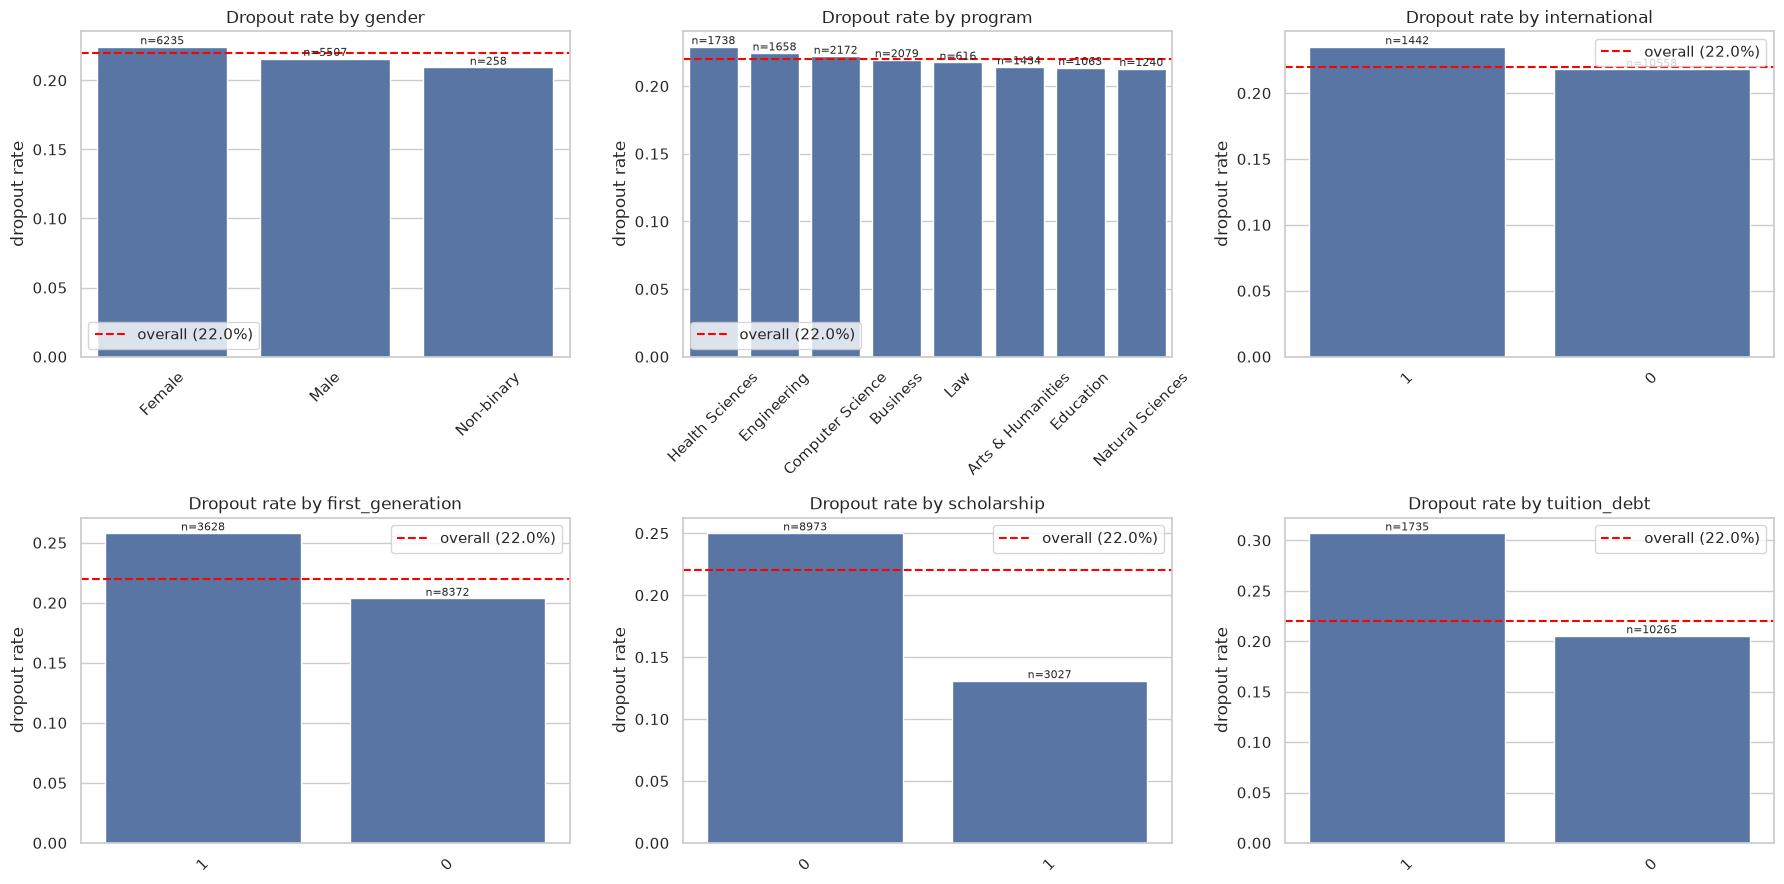

In [22]:
cat_like = categorical_cols + binary_cols
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
overall_rate = df[target].mean()
for ax, col in zip(axes.flat, cat_like):
    rate = df.groupby(col)[target].agg(["mean", "count"]).sort_values("mean", ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate["mean"], ax=ax, order=rate.index.astype(str))
    ax.axhline(overall_rate, ls="--", c="red", label=f"overall ({overall_rate:.1%})")
    ax.set_title(f"Dropout rate by {col}")
    ax.set_ylabel("dropout rate")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    for p, n in zip(ax.patches, rate["count"]):
        ax.annotate(f"n={n}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
    ax.legend()
plt.tight_layout()
plt.show()

In [23]:
from scipy.stats import chi2_contingency

rows = []
for col in cat_like:
    ct = pd.crosstab(df[col], df[target])
    chi2, p, dof, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"feature": col, "chi2": chi2, "p_value": p, "cramers_v": cramers_v})
pd.DataFrame(rows).sort_values("cramers_v", ascending=False).set_index("feature")

,chi2,p_value,cramers_v
feature,,,
scholarship,186.91,0.00,0.12
tuition_debt,89.29,0.00,0.09
first_generation,43.43,0.00,0.06
international,2.08,0.15,0.01
program,1.99,0.96,0.01
gender,1.40,0.50,0.01


#### Correlations

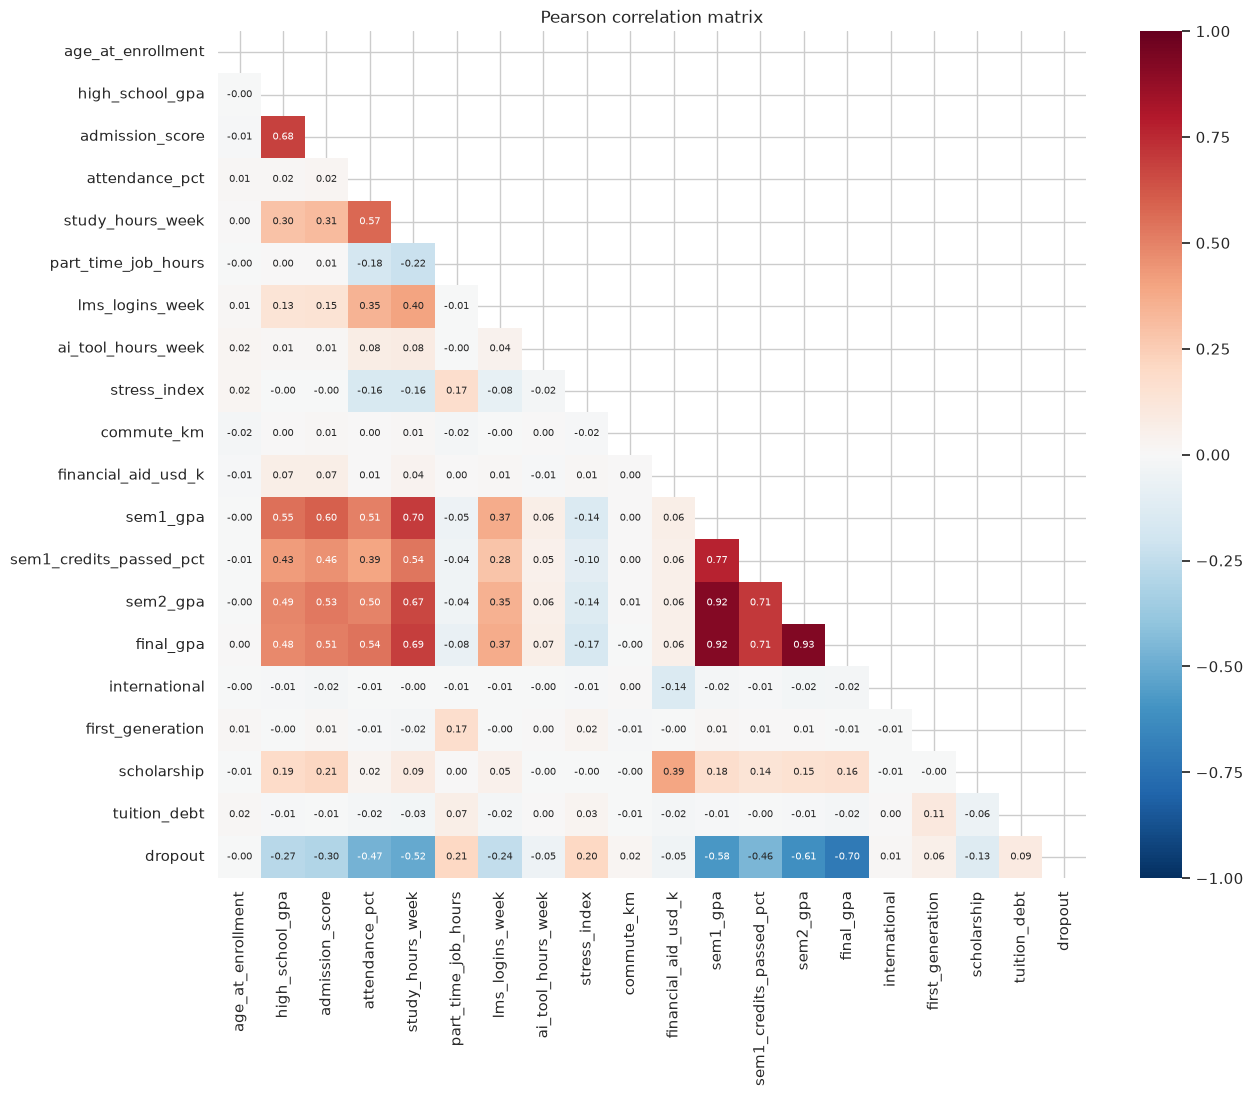

In [24]:
corr = df[numerical_cols + binary_cols + [target]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Pearson correlation matrix")
plt.show()

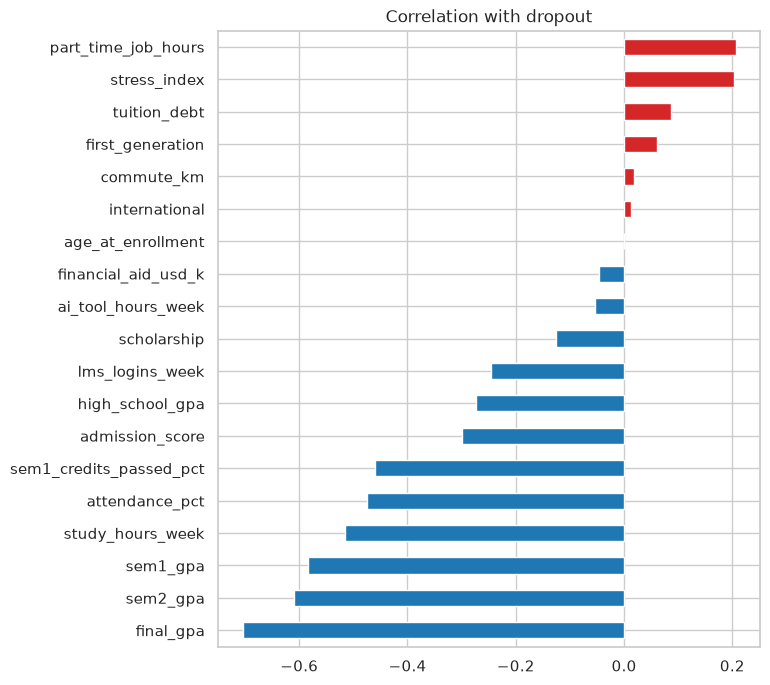

In [25]:
target_corr = corr[target].drop(target).sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
target_corr.plot.barh(ax=ax, color=np.where(target_corr > 0, "tab:red", "tab:blue"))
ax.set_title("Correlation with dropout")
plt.show()

In [26]:
# Highly correlated feature pairs (|r| > 0.7)
pairs = corr.drop(index=target, columns=target).where(np.triu(np.ones(corr.shape[0] - 1, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False)

sem2_gpa                 final_gpa                 0.93
sem1_gpa                 final_gpa                 0.92
                         sem2_gpa                  0.92
                         sem1_credits_passed_pct   0.77
sem1_credits_passed_pct  final_gpa                 0.71
                         sem2_gpa                  0.71
study_hours_week         sem1_gpa                  0.70
dtype: float64

#### Non-linear dependence: mutual information
Pearson correlation only captures linear relationships. Trees can exploit non-linear ones, so we also estimate the mutual information between each feature and the target.

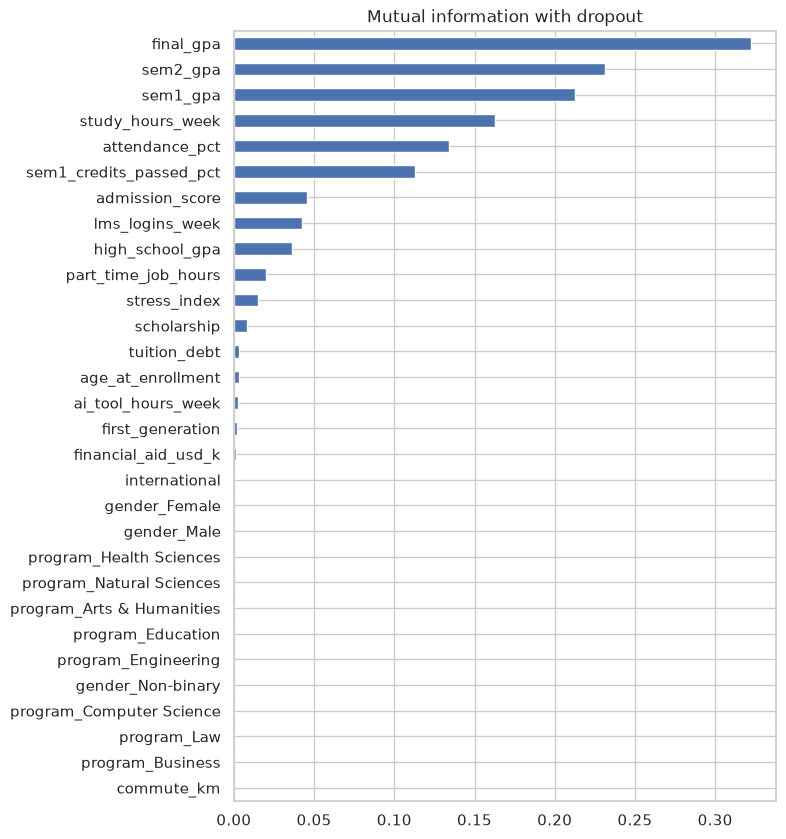

In [27]:
from sklearn.feature_selection import mutual_info_classif

X_mi = pd.get_dummies(df.drop(columns=target), columns=categorical_cols, drop_first=False)
discrete_mask = [c not in numerical_cols for c in X_mi.columns]
mi = pd.Series(
    mutual_info_classif(X_mi, df[target], discrete_features=discrete_mask, random_state=SEED),
    index=X_mi.columns,
).sort_values()

fig, ax = plt.subplots(figsize=(7, 10))
mi.plot.barh(ax=ax)
ax.set_title("Mutual information with dropout")
plt.show()

#### Potential target leakage
`final_gpa` (and possibly `sem2_gpa`) can only be measured **after** a student has finished, or dropped out of, the programme. A student who drops out typically gets a low or zero final GPA *because* they dropped out. These features are very strongly associated with the target and highly collinear with each other. If the goal is to identify at-risk students **early**, they should be excluded, or we should compare models trained with and without them.

In [28]:
gpa_cols = ["high_school_gpa", "sem1_gpa", "sem2_gpa", "final_gpa"]
display(df[gpa_cols].corr())
display(df.groupby(target)[gpa_cols].describe().T)

for col in ["sem1_gpa", "sem2_gpa", "final_gpa"]:
    zeros = df[col] == 0
    print(f"{col}: {zeros.sum()} zeros, dropout rate among them = {df.loc[zeros, target].mean():.0%}")

,high_school_gpa,sem1_gpa,sem2_gpa,final_gpa
high_school_gpa,1.00,0.55,0.49,0.48
sem1_gpa,0.55,1.00,0.92,0.92
sem2_gpa,0.49,0.92,1.00,0.93
final_gpa,0.48,0.92,0.93,1.00


dropout                     0       1
high_school_gpa count 9360.00 2640.00
                mean     3.07    2.75
                std      0.48    0.46
                min      1.50    1.50
                25%      2.75    2.44
                50%      3.08    2.74
                75%      3.40    3.05
                max      4.00    4.00
sem1_gpa        count 9360.00 2640.00
                mean     2.89    1.93
                std      0.57    0.49
                min      1.16    0.00
                25%      2.49    1.61
                50%      2.87    1.95
                75%      3.29    2.27
                max      4.00    3.51
sem2_gpa        count 9360.00 2640.00
                mean     2.92    1.81
                std      0.61    0.54
                min      1.08    0.00
                25%      2.48    1.46
                50%      2.90    1.81
                75%      3.37    2.16
                max      4.00    3.73
final_gpa       count 9360.00 2640.00
                mean     2.91    1.44
                std      0.63    0.56
                min      0.82    0.00
                25%      2.46    1.07
                50%      2.90    1.44
                75%      3.38    1.82
                max      4.00    3.61

sem1_gpa: 1 zeros, dropout rate among them = 100%
sem2_gpa: 3 zeros, dropout rate among them = 100%
final_gpa: 16 zeros, dropout rate among them = 100%


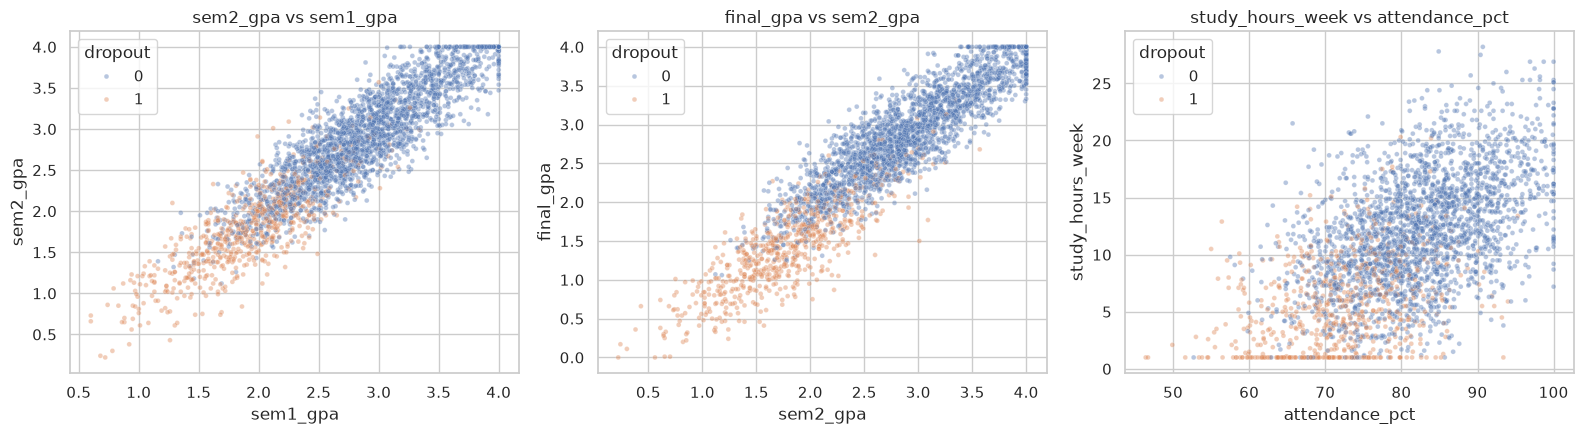

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (x, y) in zip(axes, [("sem1_gpa", "sem2_gpa"), ("sem2_gpa", "final_gpa"), ("attendance_pct", "study_hours_week")]):
    sns.scatterplot(data=df.sample(3000, random_state=SEED), x=x, y=y, hue=target, alpha=0.4, s=12, ax=ax)
    ax.set_title(f"{y} vs {x}")
plt.tight_layout()
plt.show()

#### EDA summary and implications for Random Forest + Bagging
- **Data quality**: no missing values and no duplicates. `student_id` has been dropped.
- **Class imbalance**: about 78% stayed and 22% dropped out. Use `stratify=y` in `train_test_split` / `StratifiedKFold`, consider `class_weight="balanced_subsample"`, and evaluate with recall, F1, ROC-AUC and PR-AUC.
- **Preprocessing**: one-hot encode `gender` and `program`. Scaling is **not** required for tree ensembles. Skewed features (`commute_km`, `lms_logins_week`, `ai_tool_hours_week`, `part_time_job_hours`) need no transformation.
- **Strongest signals**: semester/final GPA, study hours, attendance, credits passed and admission score lower dropout risk. Stress index, part-time job hours and tuition debt raise it. Demographics (`age`, `international`, `commute_km`) carry little signal.
- **Multicollinearity**: `sem1_gpa`, `sem2_gpa` and `final_gpa` are highly correlated (r > 0.9). This does not hurt predictive accuracy for trees, but it splits impurity-based feature importance across them. Prefer permutation importance when interpreting.
- **Leakage risk**: decide whether `final_gpa` (and `sem2_gpa`) is available at prediction time. Train an "early warning" model without them for comparison.

### Train/Test Split
We hold out 30% of the data as a test set and train on the other 70%.
- `stratify=y` keeps the roughly 78/22 class ratio the same in both sets.
- `random_state=SEED` makes the split reproducible.
- `gender` and `program` are one-hot encoded. This is a per-row transformation that learns nothing from the data, so doing it before the split does not leak test information. Tree ensembles need no scaling.
- `leakage_cols` lets us exclude features that would not be available at prediction time (see the leakage section above). Leave it empty to use all features.

In [ ]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.30
leakage_cols = []  # e.g. ["final_gpa", "sem2_gpa"] for an early-warning model

X = df.drop(columns=[target] + leakage_cols)
y = df[target]
X = pd.get_dummies(X, columns=categorical_cols, drop_first=False, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Features ({X.shape[1]}): {list(X.columns)}")

In [ ]:
# Check that stratification preserved the class distribution
pd.DataFrame({
    "full": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).rename_axis(target)